<img src="https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcRHuCwrMl7_P1P9qfrC17WW2nkhg79X25bi0A&s" width="500"/>

## Universidad Iberoamericana

**Facultad de Ingeniería**  
**Ingeniería de Software**  
**Asignatura:** Inteligencia Artificial  
**Actividad 3:** Métodos de aprendizaje supervisado  
**Tema:** Predicción de retrasos ferroviarios con Árbol de Decisión  

---

## Problema

El objetivo es predecir si una observación ferroviaria tendrá un **retraso superior a 15 minutos** usando variables disponibles antes del resultado: fecha, posición de la parada, distancia desde el origen, tipo de tren y zona ferroviaria.

Se utiliza un solo método supervisado: **Árbol de Decisión**. Es adecuado para esta actividad porque permite clasificar y visualizar las reglas aprendidas.

## Fuente de datos

Dataset público de Kaggle: **Indian Railways - Delay Dataset** (`rxydenxd/indian-railways-delay-dataset`).

El notebook descarga el dataset con `kagglehub.dataset_download()` y une las tablas necesarias para construir el modelo.

## 1. Instalación e importación

In [1]:
# ============================================================
# 1. INSTALACIÓN
# ============================================================

# En Colab instala KaggleHub si no está disponible.
# En validación local con DATASET_LOCAL_DIR no se instala nada.
import os
import importlib.util

if os.environ.get("DATASET_LOCAL_DIR") is None and importlib.util.find_spec("kagglehub") is None:
    !pip -q install kagglehub


In [2]:
# ============================================================
# 2. IMPORTACIÓN DE LIBRERÍAS
# ============================================================

from pathlib import Path
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    roc_curve, roc_auc_score
)

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (8, 5)


## 2. Descarga y preparación del dataset

In [3]:
# ============================================================
# 3. CONFIGURACIÓN
# ============================================================

DATASET_HANDLE = "rxydenxd/indian-railways-delay-dataset"
MAX_LECTURA = 250000
MUESTRA_MAX = 100000
TARGET = "is_delayed"

# En Colab se deja None para descargar desde Kaggle.
# Para pruebas locales se puede usar la variable de entorno DATASET_LOCAL_DIR.
DATASET_LOCAL = os.environ.get("DATASET_LOCAL_DIR")

OUTPUT_DIR = Path("salidas_actividad3")
OUTPUT_DIR.mkdir(exist_ok=True)


In [4]:
# ============================================================
# 4. FUNCIONES DE APOYO
# ============================================================

def normalizar_columnas(df):
    # Nombres consistentes: minúsculas, sin espacios y con guion bajo.
    df = df.copy()
    df.columns = (
        df.columns.astype(str)
        .str.strip()
        .str.lower()
        .str.replace(" ", "_", regex=False)
        .str.replace("-", "_", regex=False)
    )
    return df

def leer_tabla(ruta, nrows=None):
    # Lee CSV o Parquet según el formato del archivo.
    ruta = Path(ruta)
    if ruta.suffix.lower() == ".csv":
        return pd.read_csv(ruta, nrows=nrows, low_memory=False)
    if ruta.suffix.lower() in [".parquet", ".pq"]:
        df_tmp = pd.read_parquet(ruta)
        return df_tmp.head(nrows) if nrows else df_tmp
    raise ValueError(f"Formato no soportado: {ruta}")

def buscar_archivo(carpeta, texto):
    # Busca un archivo del dataset por parte del nombre.
    candidatos = [p for p in Path(carpeta).rglob("*") if p.is_file() and texto in p.stem.lower()]
    if not candidatos:
        raise FileNotFoundError(f"No se encontró archivo con: {texto}")
    return candidatos[0]


In [5]:
# ============================================================
# 5. DESCARGA PÚBLICA DESDE KAGGLE
# ============================================================

if DATASET_LOCAL:
    dataset_path = Path(DATASET_LOCAL)
else:
    import kagglehub
    dataset_path = Path(kagglehub.dataset_download(DATASET_HANDLE))

archivo_delay = buscar_archivo(dataset_path, "combined_delay")
archivo_schedule = buscar_archivo(dataset_path, "combined_schedule")
archivo_trenes = buscar_archivo(dataset_path, "train_details")
archivo_estaciones = buscar_archivo(dataset_path, "station_full_names")

print("Carpeta del dataset:", dataset_path)
print("Tabla retrasos:", archivo_delay.name)
print("Tabla horarios:", archivo_schedule.name)
print("Tabla trenes:", archivo_trenes.name)
print("Tabla estaciones:", archivo_estaciones.name)


Carpeta del dataset: /mnt/data/ibero_final_packages/fixture_indian_railways
Tabla retrasos: combined_delay.csv
Tabla horarios: combined_schedule.csv
Tabla trenes: train_details.csv
Tabla estaciones: station_full_names.csv


In [6]:
# ============================================================
# 6. LECTURA Y UNIÓN DE TABLAS
# ============================================================

delay = normalizar_columnas(leer_tabla(archivo_delay, MAX_LECTURA))
schedule = normalizar_columnas(leer_tabla(archivo_schedule))
trenes = normalizar_columnas(leer_tabla(archivo_trenes))
estaciones = normalizar_columnas(leer_tabla(archivo_estaciones))

# Nombres reales del dataset.
schedule = schedule.rename(columns={"station_no": "stop_sequence"})
estaciones = estaciones.rename(columns={"station_zone": "zone"})

# Asegurar nombre común para el tipo de tren.
if "train_type" not in trenes.columns:
    tipo_col = next((c for c in ["type_code", "train_type_code", "type"] if c in trenes.columns), None)
    if tipo_col:
        trenes = trenes.rename(columns={tipo_col: "train_type"})
    else:
        trenes["train_type"] = "desconocido"

# Llaves de unión como texto.
for tabla in [delay, schedule, trenes]:
    tabla["train_no"] = tabla["train_no"].astype(str).str.strip()
for tabla in [delay, schedule, estaciones]:
    tabla["station_name"] = tabla["station_name"].astype(str).str.strip()

# Muestra para que Colab trabaje rápido.
if len(delay) > MUESTRA_MAX:
    delay = delay.sample(MUESTRA_MAX, random_state=42).reset_index(drop=True)

# Evitar duplicados antes de unir.
schedule = schedule.drop_duplicates(["train_no", "station_name"])
trenes = trenes.drop_duplicates("train_no")
estaciones = estaciones.drop_duplicates("station_name")

df = (
    delay
    .merge(schedule[["train_no", "station_name", "stop_sequence", "distance_from_origin"]],
           on=["train_no", "station_name"], how="left")
    .merge(trenes[["train_no", "train_type"]], on="train_no", how="left")
    .merge(estaciones[["station_name", "zone"]], on="station_name", how="left")
)

print("Dimensiones después de unir tablas:", df.shape)
display(df.head())


Dimensiones después de unir tablas: (8000, 8)


,date,train_no,station_name,delay,stop_sequence,distance_from_origin,train_type,zone
0,2026-01-05,10077,ST019,22.79,10,411,SF,Central
1,2026-01-25,10059,ST005,38.00,11,425,EXP,East
2,2026-01-27,10033,ST027,19.80,4,175,PASS,North
3,2026-04-23,10060,ST016,0.25,6,290,SF,East
4,2026-01-29,10069,ST011,16.35,2,39,PASS,North


In [7]:
# ============================================================
# 7. LIMPIEZA Y VARIABLE OBJETIVO
# ============================================================

df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["delay"] = pd.to_numeric(df["delay"], errors="coerce")
df["stop_sequence"] = pd.to_numeric(df["stop_sequence"], errors="coerce")
df["distance_from_origin"] = pd.to_numeric(df["distance_from_origin"], errors="coerce")

# Variables temporales simples.
df["month"] = df["date"].dt.month
df["day_of_week"] = df["date"].dt.dayofweek

# Clasificación binaria: retraso mayor a 15 minutos.
df[TARGET] = (df["delay"] > 15).astype(int)

# El modelo no debe aprender desde la respuesta real.
columnas_modelo = [
    "stop_sequence", "distance_from_origin", "month", "day_of_week",
    "train_type", "zone", TARGET
]

df_modelo = df[columnas_modelo].dropna().copy()

print("Dataset final para modelado:", df_modelo.shape)
display(df_modelo.head())


Dataset final para modelado: (8000, 7)


,stop_sequence,distance_from_origin,month,day_of_week,train_type,zone,is_delayed
0,10,411,1,0,SF,Central,1
1,11,425,1,6,EXP,East,1
2,4,175,1,1,PASS,North,1
3,6,290,4,3,SF,East,0
4,2,39,1,3,PASS,North,1


## 3. Mini EDA

In [8]:
# ============================================================
# 8. RESUMEN GENERAL
# ============================================================

print("Filas:", df_modelo.shape[0])
print("Columnas:", df_modelo.shape[1])

display(df_modelo.describe(include="all").T)


Filas: 8000
Columnas: 7


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
stop_sequence,8000.0,NaN,NaN,NaN,6.46375,3.666895,1.0,3.0,6.0,9.0,15.0
distance_from_origin,8000.0,NaN,NaN,NaN,284.550125,199.619129,0.0,115.0,270.0,429.0,895.0
month,8000.0,NaN,NaN,NaN,2.490875,1.125977,1.0,1.0,3.0,3.0,4.0
day_of_week,8000.0,NaN,NaN,NaN,3.00475,1.984495,0.0,1.0,3.0,5.0,6.0
train_type,8000,4,SF,2668,NaN,NaN,NaN,NaN,NaN,NaN,NaN
zone,8000,5,East,2073,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_delayed,8000.0,NaN,NaN,NaN,0.754875,0.430188,0.0,1.0,1.0,1.0,1.0


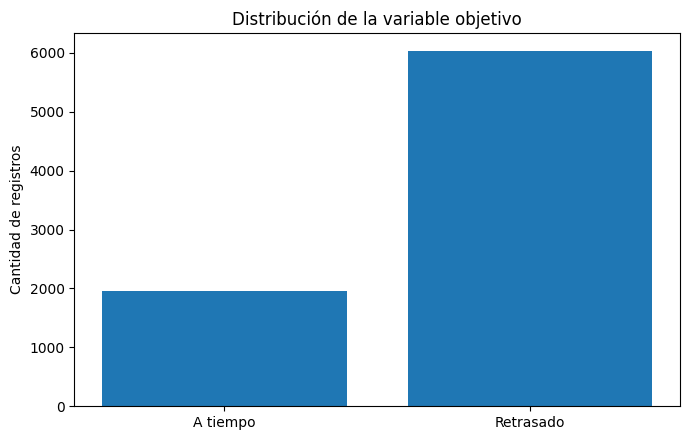

In [9]:
# ============================================================
# 9. DISTRIBUCIÓN DE LA VARIABLE OBJETIVO
# ============================================================

conteo = df_modelo[TARGET].value_counts().reindex([0, 1], fill_value=0)

plt.figure(figsize=(7, 4.5))
plt.bar(["A tiempo", "Retrasado"], conteo.values)
plt.title("Distribución de la variable objetivo")
plt.ylabel("Cantidad de registros")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_objetivo.png", dpi=160)
plt.show()


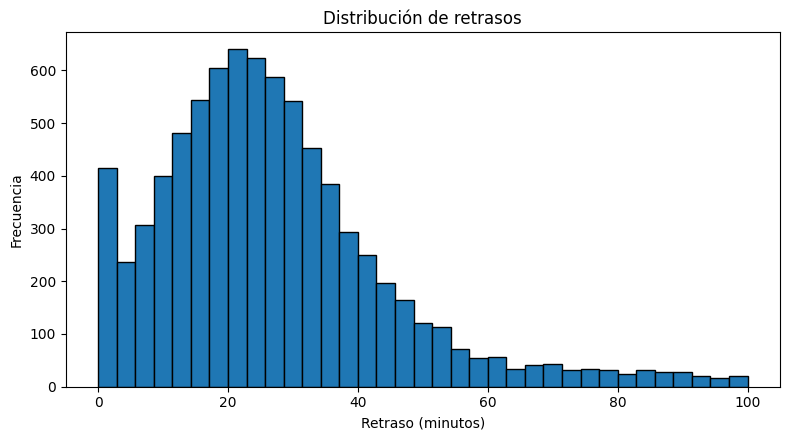

In [10]:
# ============================================================
# 10. DISTRIBUCIÓN DEL RETRASO
# ============================================================

limite = df["delay"].quantile(0.99)

plt.figure(figsize=(8, 4.5))
plt.hist(df.loc[df["delay"] <= limite, "delay"], bins=35, edgecolor="black")
plt.title("Distribución de retrasos")
plt.xlabel("Retraso (minutos)")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_distribucion_retraso.png", dpi=160)
plt.show()


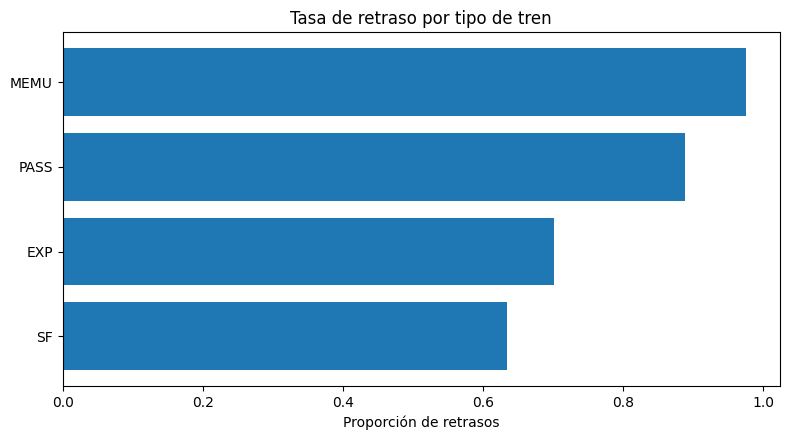

In [11]:
# ============================================================
# 11. TASA DE RETRASO POR TIPO DE TREN
# ============================================================

tasa_tipo = df_modelo.groupby("train_type")[TARGET].mean().sort_values()

plt.figure(figsize=(8, 4.5))
plt.barh(tasa_tipo.index.astype(str), tasa_tipo.values)
plt.title("Tasa de retraso por tipo de tren")
plt.xlabel("Proporción de retrasos")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_tasa_tipo_tren.png", dpi=160)
plt.show()


## 4. Entrenamiento del Árbol de Decisión

In [12]:
# ============================================================
# 12. PREPARACIÓN DE VARIABLES
# ============================================================

X = df_modelo.drop(columns=[TARGET])
y = df_modelo[TARGET]

variables_numericas = ["stop_sequence", "distance_from_origin", "month", "day_of_week"]
variables_categoricas = ["train_type", "zone"]

preprocesador = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), variables_numericas),
        ("cat", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), variables_categoricas),
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)


Entrenamiento: (5600, 6)
Prueba: (2400, 6)


In [13]:
# ============================================================
# 13. MODELO SUPERVISADO: ÁRBOL DE DECISIÓN
# ============================================================

modelo = Pipeline(steps=[
    ("preprocesamiento", preprocesador),
    ("arbol", DecisionTreeClassifier(
        max_depth=4,
        min_samples_leaf=30,
        class_weight="balanced",
        random_state=42
    ))
])

modelo.fit(X_train, y_train)

pred = modelo.predict(X_test)
proba = modelo.predict_proba(X_test)[:, 1]

print("Modelo entrenado correctamente.")


Modelo entrenado correctamente.


## 5. Resultados y validación

In [14]:
# ============================================================
# 14. MÉTRICAS DE EVALUACIÓN
# ============================================================

metricas = {
    "accuracy": accuracy_score(y_test, pred),
    "precision": precision_score(y_test, pred, zero_division=0),
    "recall": recall_score(y_test, pred, zero_division=0),
    "f1": f1_score(y_test, pred, zero_division=0),
    "roc_auc": roc_auc_score(y_test, proba),
}

display(pd.DataFrame([metricas]).round(4))
print(classification_report(y_test, pred, target_names=["A tiempo", "Retrasado"]))


,accuracy,precision,recall,f1,roc_auc
0,0.7262,0.8863,0.7312,0.8013,0.7683


              precision    recall  f1-score   support

    A tiempo       0.46      0.71      0.56       588
   Retrasado       0.89      0.73      0.80      1812

    accuracy                           0.73      2400
   macro avg       0.67      0.72      0.68      2400
weighted avg       0.78      0.73      0.74      2400



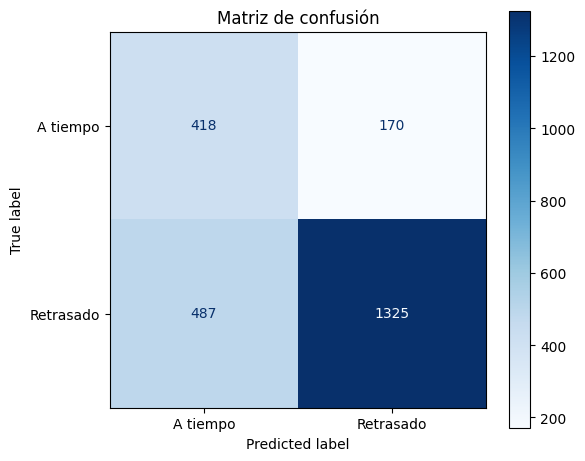

In [15]:
# ============================================================
# 15. MATRIZ DE CONFUSIÓN
# ============================================================

matriz = confusion_matrix(y_test, pred)

plt.figure(figsize=(6, 5))
ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["A tiempo", "Retrasado"]
).plot(values_format="d", cmap="Blues", ax=plt.gca())
plt.title("Matriz de confusión")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "04_matriz_confusion.png", dpi=160)
plt.show()


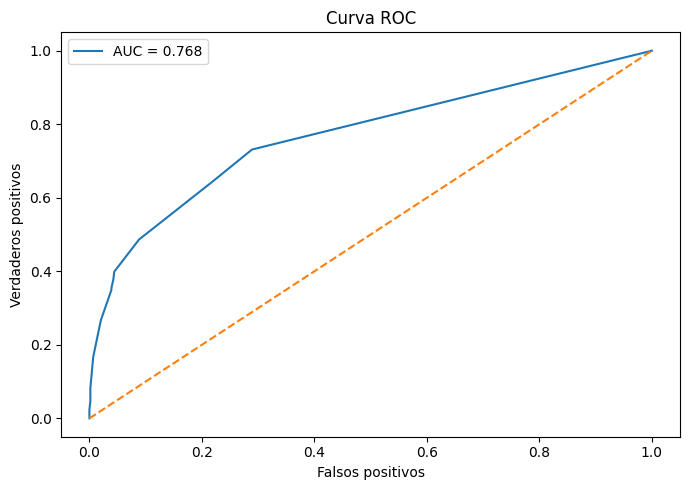

In [16]:
# ============================================================
# 16. CURVA ROC
# ============================================================

fpr, tpr, _ = roc_curve(y_test, proba)
auc = roc_auc_score(y_test, proba)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.title("Curva ROC")
plt.xlabel("Falsos positivos")
plt.ylabel("Verdaderos positivos")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_curva_roc.png", dpi=160)
plt.show()


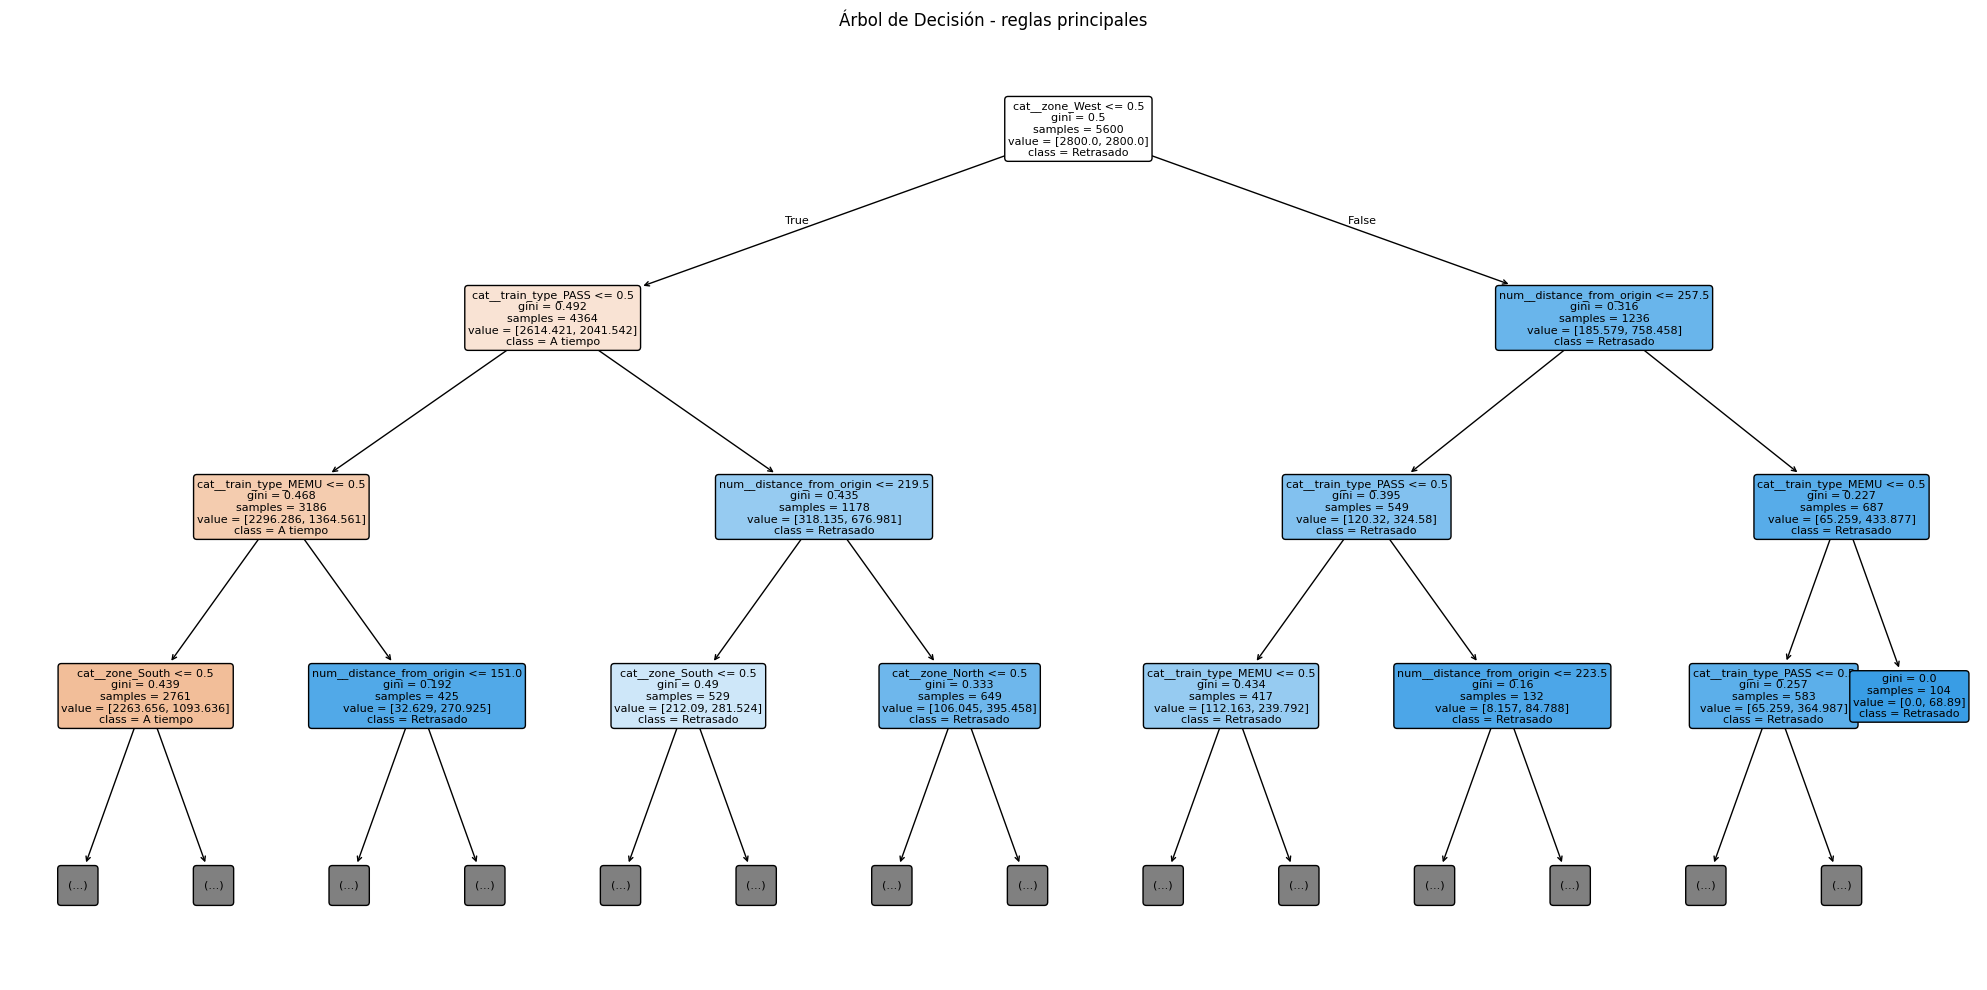

In [17]:
# ============================================================
# 17. VISUALIZACIÓN DEL ÁRBOL
# ============================================================

# Obtener nombres de variables después del preprocesamiento.
feature_names = modelo.named_steps["preprocesamiento"].get_feature_names_out()
arbol = modelo.named_steps["arbol"]

plt.figure(figsize=(20, 10))
plot_tree(
    arbol,
    feature_names=feature_names,
    class_names=["A tiempo", "Retrasado"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)
plt.title("Árbol de Decisión - reglas principales")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "06_arbol_decision.png", dpi=180, bbox_inches="tight")
plt.show()


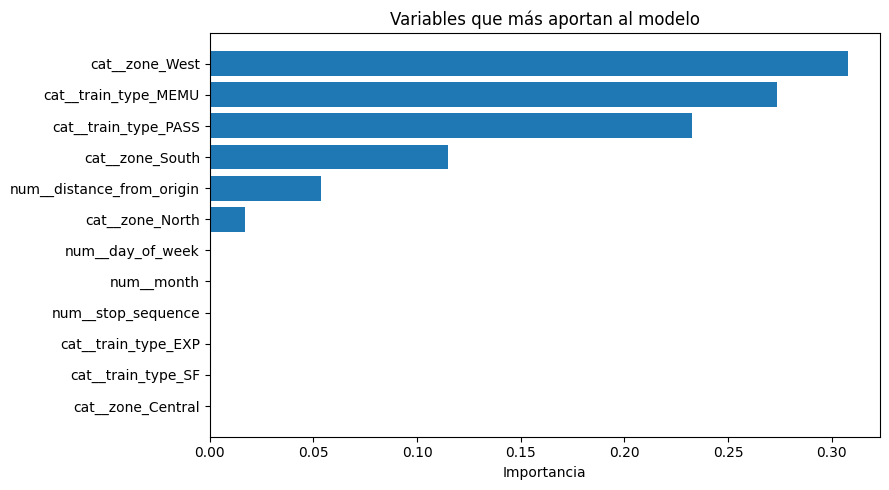

,variable,importancia
12,cat__zone_West,0.307916
5,cat__train_type_MEMU,0.273727
6,cat__train_type_PASS,0.232555
11,cat__zone_South,0.114774
1,num__distance_from_origin,0.053838
10,cat__zone_North,0.017189
3,num__day_of_week,0.000000
2,num__month,0.000000
0,num__stop_sequence,0.000000
4,cat__train_type_EXP,0.000000


In [18]:
# ============================================================
# 18. IMPORTANCIA DE VARIABLES
# ============================================================

importancias = pd.DataFrame({
    "variable": feature_names,
    "importancia": arbol.feature_importances_
}).sort_values("importancia", ascending=False).head(12)

plt.figure(figsize=(9, 5))
plt.barh(importancias["variable"][::-1], importancias["importancia"][::-1])
plt.title("Variables que más aportan al modelo")
plt.xlabel("Importancia")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "07_importancia_variables.png", dpi=160, bbox_inches="tight")
plt.show()

display(importancias)


In [19]:
# ============================================================
# 19. PRUEBAS AUTOMÁTICAS
# ============================================================

pruebas = []

def ok(nombre, condicion):
    pruebas.append({"prueba": nombre, "resultado": "OK" if condicion else "FALLA"})
    assert condicion, nombre

ok("El dataset final tiene registros", len(df_modelo) > 0)
ok("La variable objetivo existe", TARGET in df_modelo.columns)
ok("La variable delay no se usa como predictor", "delay" not in X.columns)
ok("Train y test tienen datos", len(X_train) > 0 and len(X_test) > 0)
ok("El árbol fue entrenado", hasattr(arbol, "tree_"))
ok("La matriz de confusión tiene forma 2x2", matriz.shape == (2, 2))
ok("Las probabilidades están entre 0 y 1", np.all((proba >= 0) & (proba <= 1)))
ok("ROC-AUC calculado", not np.isnan(auc))
ok("Existen importancias de variables", importancias["importancia"].sum() > 0)
ok("El reporte usa un solo método", modelo.named_steps["arbol"].__class__.__name__ == "DecisionTreeClassifier")
ok("Se generaron imágenes", (OUTPUT_DIR / "06_arbol_decision.png").exists())

resultado_pruebas = pd.DataFrame(pruebas)
display(resultado_pruebas)
print("Pruebas aprobadas:", (resultado_pruebas["resultado"] == "OK").sum(), "/", len(resultado_pruebas))


,prueba,resultado
0,El dataset final tiene registros,OK
1,La variable objetivo existe,OK
2,La variable delay no se usa como predictor,OK
3,Train y test tienen datos,OK
4,El árbol fue entrenado,OK
5,La matriz de confusión tiene forma 2x2,OK
6,Las probabilidades están entre 0 y 1,OK
7,ROC-AUC calculado,OK
8,Existen importancias de variables,OK
9,El reporte usa un solo método,OK


Pruebas aprobadas: 11 / 11


## Conclusión

El Árbol de Decisión permite clasificar observaciones ferroviarias como retrasadas o a tiempo. Además, la visualización del árbol y la importancia de variables permiten explicar qué condiciones influyen más en la predicción.